In [21]:
import numpy as np
import matplotlib.pyplot as plt


class BernoulliGLM:
    def __init__(self, learning_rate=0.1, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations

    @staticmethod
    def _sigmoid(z):
        z = np.clip(z, -500, 500)
        return 1.0 / (1.0 + np.exp(-z))

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float).ravel()
        n_samples, n_features = X.shape
        self.beta = np.zeros(n_features)
        self.bias = 0.0
        self.loss_history = []
        eps = 1e-12

        for _ in range(self.n_iterations):
            p = self._sigmoid(X @ self.beta + self.bias)
            error = p - y
            self.loss_history.append(
                -np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))
            )
            self.beta -= self.learning_rate * (X.T @ error) / n_samples
            self.bias -= self.learning_rate * error.mean()
        return self

    def predict_proba(self, X):
        return self._sigmoid(np.asarray(X, dtype=float) @ self.beta + self.bias)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)


In [22]:
def train_test_split_np(X, y, test_size=0.2, seed=42):
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(X))
    n_test = int(len(X) * test_size)
    return X[idx[n_test:]], X[idx[:n_test]], y[idx[n_test:]], y[idx[:n_test]]

def standardize_fit(X):
    mean, std = X.mean(axis=0), X.std(axis=0)
    std[std == 0] = 1.0
    return mean, std

def standardize_apply(X, mean, std):
    return (X - mean) / std

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

def bce(y, p, eps=1e-12):
    return -np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))

def confusion(y, pred):
    tp = np.sum((y == 1) & (pred == 1)); tn = np.sum((y == 0) & (pred == 0))
    fp = np.sum((y == 0) & (pred == 1)); fn = np.sum((y == 1) & (pred == 0))
    return tp, tn, fp, fn

def report(name, y, pred):
    tp, tn, fp, fn = confusion(y, pred)
    acc = (tp + tn) / len(y)
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    print(f"[{name}] acc={acc:.4f} precision={prec:.4f} recall={rec:.4f} f1={f1:.4f}")
    print(f"           confusion: TP={tp} TN={tn} FP={fp} FN={fn}")



In [ ]:
def irls(A, y, n_iter=50, tol=1e-10, ridge=1e-8):

    # A = N X F
    
    # w = 1 X F
    w = np.zeros(A.shape[1])
    # w는 열벡터? or array?
    
    for _ in range(n_iter):
        # P = dot(A W) --> N X 1
        # @는 행렬곱 아니었나?
        # 내적도 되나?
        # N X F F X 1 ?
        # 행렬곱은 내적을 포함하기 때문에 모양에 따라서
        # 알아서 처리 되도록 한다
        p = sigmoid(A @ w)
        # p --> N x F X F X 1 -- > N X 1 데이터 마다 확률 값
        # 벡터
        
        # sigmoid 미분

        W = p * (1 - p)
        
        grad = A.T @ (p - y)
        
        #H는 2차 미분함수의 값인데 A와 W의 위치가 바뀐거 아닌가?
        #H = XTSX인데
        #A - > N x F
        #W는 (N,)
        # W를 벡터로 만들어서 (N,1) 바꾸고
        # * 성분별곱
        
        H = A.T @ (A * W[:, None]) + ridge * np.eye(A.shape[1])  # 수치 안정용 아주 작은 항
        
        #역행렬 푸는 식
        
        step = np.linalg.solve(H, grad)
        w -= step
        if np.max(np.abs(step)) < tol:
            break
    return w

train=(456, 30), test=(113, 30), 양성 비율(train)=0.618

[IRLS] acc=0.9381 precision=0.9595 recall=0.9467 f1=0.9530
           confusion: TP=71 TN=35 FP=3 FN=4
[GLM 표준화] acc=0.9646 precision=0.9494 recall=1.0000 f1=0.9740
           confusion: TP=75 TN=34 FP=4 FN=0

계수 비교 (표준화 데이터 기준, 앞 10개)
feature                         IRLS       GLM
mean radius                 328.3516   -0.5113
mean texture                -23.9940   -0.5363
mean perimeter              -90.8008   -0.5051
mean area                   -31.7043   -0.5903
mean smoothness              28.9478   -0.3590
mean compactness            126.3947    0.5196
mean concavity              100.8376   -1.0435
mean concave points        -250.9742   -1.1528
mean symmetry                -5.1844    0.1432
mean fractal dimension        5.0999    0.5252
bias                        -28.1984   -0.2374

최대 계수 차이: 4.67e+02

[비표준화] 학습률별 최종 손실
  lr=0.1      final loss = 2.545
  lr=0.001    final loss = 2.361
  lr=1e-05    final loss = 0.2015
  lr=1e-

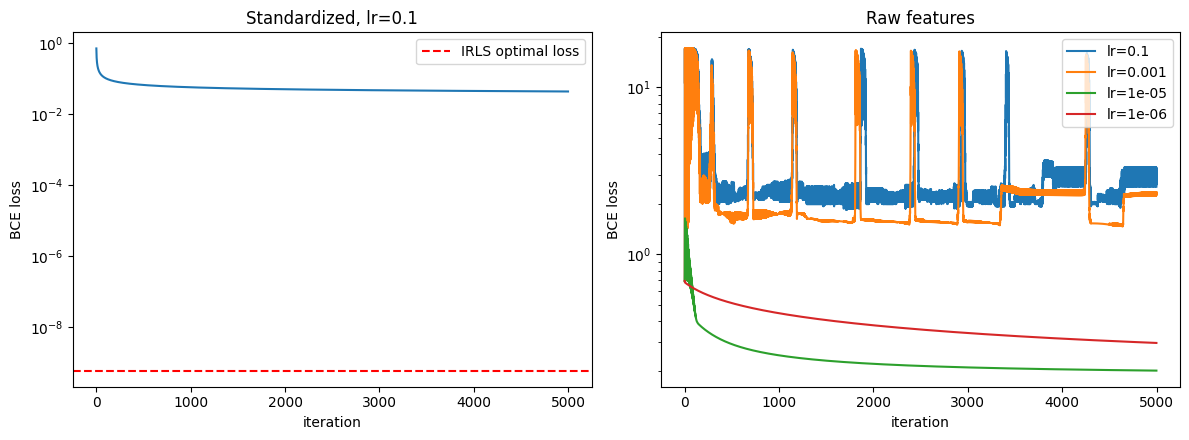

In [24]:
from sklearn.datasets import load_breast_cancer   # 최초 1회만 필요
d = load_breast_cancer()
X, y, feature_names = d.data, d.target.astype(float), d.feature_names
# np.save("bc_X.npy", X); np.save("bc_y.npy", y)
# X, y = np.load("bc_X.npy"), np.load("bc_y.npy")   # 이후엔 numpy만으로

X_train, X_test, y_train, y_test = train_test_split_np(X, y)
print(f"train={X_train.shape}, test={X_test.shape}, 양성 비율(train)={y_train.mean():.3f}\n")

# ---------- 2. 표준화 (train 통계만 사용) ----------
mean, std = standardize_fit(X_train)
X_train_s = standardize_apply(X_train, mean, std)
X_test_s = standardize_apply(X_test, mean, std)

# ---------- 3. 기준선: IRLS ----------
A_train = np.c_[X_train_s, np.ones(len(X_train_s))]
w_irls = irls(A_train, y_train)
irls_beta, irls_bias = w_irls[:-1], w_irls[-1]
irls_pred = (sigmoid(X_test_s @ irls_beta + irls_bias) >= 0.5).astype(int)
report("IRLS", y_test, irls_pred)

# ---------- 4. GLM (표준화 데이터) ----------
glm = BernoulliGLM(learning_rate=0.1, n_iterations=5000).fit(X_train_s, y_train)
report("GLM 표준화", y_test, glm.predict(X_test_s))

print("\n계수 비교 (표준화 데이터 기준, 앞 10개)")
print(f"{'feature':<26}{'IRLS':>10}{'GLM':>10}")
for name, b1, b2 in list(zip(feature_names, irls_beta, glm.beta))[:10]:
    print(f"{name:<26}{b1:>10.4f}{b2:>10.4f}")
print(f"{'bias':<26}{irls_bias:>10.4f}{glm.bias:>10.4f}")
print(f"\n최대 계수 차이: {np.max(np.abs(irls_beta - glm.beta)):.2e}")

# ---------- 5. 비표준화 데이터 (스케일 민감도) ----------
print("\n[비표준화] 학습률별 최종 손실")
raw_results = {}
for lr in [1e-1, 1e-3, 1e-5, 1e-6]:
    with np.errstate(all="ignore"):
        m = BernoulliGLM(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)
    raw_results[lr] = m.loss_history
    print(f"  lr={lr:<8} final loss = {m.loss_history[-1]:.4g}")

# ---------- 6. 임계값 변화 ----------
print("\n[임계값별 precision/recall]")
proba = glm.predict_proba(X_test_s)
for th in [0.3, 0.5, 0.7, 0.9]:
    pred = (proba >= th).astype(int)
    tp, tn, fp, fn = confusion(y_test, pred)
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    print(f"  th={th}: precision={prec:.4f} recall={rec:.4f}")

# ---------- 7. 시각화 ----------
irls_loss = bce(y_train, sigmoid(A_train @ w_irls))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(glm.loss_history)
axes[0].axhline(irls_loss, color="r", ls="--", label="IRLS optimal loss")
axes[0].set_yscale("log")
axes[0].set(title="Standardized, lr=0.1", xlabel="iteration", ylabel="BCE loss")
axes[0].legend()

for lr, hist in raw_results.items():
    h = np.array(hist); h[~np.isfinite(h)] = np.nan
    axes[1].plot(h, label=f"lr={lr}")
axes[1].set_yscale("log")
axes[1].set(title="Raw features", xlabel="iteration", ylabel="BCE loss")
axes[1].legend()

plt.tight_layout()
plt.show()